In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
sample_a = pd.read_csv(r'C:\IDE\2 семестр\Внедрение моделей ML\AB test\4.6-4.9\ab_test-redesign_sample_a\ab_test-redesign_sample_a.csv')
sample_b = pd.read_csv(r'C:\IDE\2 семестр\Внедрение моделей ML\AB test\4.6-4.9\ab_test-redesign_sample_b\ab_test-redesign_sample_b.csv')

In [3]:
sample_a.head()

,date,cid,transactions,revenue,group
0,2020-11-06,1.001648e+09,0,0,A
1,2020-11-06,1.001936e+09,0,0,A
2,2020-11-06,1.003214e+08,0,0,A
3,2020-11-06,1.004393e+09,0,0,A
4,2020-11-06,1.006382e+09,0,0,A


In [4]:
sample_a['date'] = pd.to_datetime(sample_a['date'], format='%Y-%m-%d')

In [5]:

sample_b['date'] = pd.to_datetime(sample_b['date'], format='%Y-%m-%d')

In [6]:
daily_data_a = sample_a.groupby('date').agg({
    'cid':'count',
    'transactions':'sum',
    'revenue':'sum'
}).reset_index()
daily_data_a.head()

,date,cid,transactions,revenue
0,2020-11-06,2576,16,1577279
1,2020-11-07,2704,23,1721886
2,2020-11-08,3354,25,846051
3,2020-11-09,3234,18,708830
4,2020-11-10,3022,29,826984


In [7]:
daily_data_b = sample_b.groupby('date').agg({
    'cid':'count',
    'transactions':'sum',
    'revenue':'sum'
}).reset_index()
daily_data_b.head()

,date,cid,transactions,revenue
0,2020-11-06,2499,19,996645
1,2020-11-07,2804,19,555499
2,2020-11-08,3291,24,3044842
3,2020-11-09,3062,25,1285836
4,2020-11-10,3072,30,2414726


In [8]:
daily_data_a.loc[:, 'cum_users_count'] = daily_data_a['cid'].cumsum()
# выводим время, количество посетителей и кумулятивное количество посетителей
daily_data_a.loc[:, 'cum_transactions'] = daily_data_a['transactions'].cumsum()
daily_data_a.loc[:, 'cum_revenue'] = daily_data_a['revenue'].cumsum()
display(daily_data_a[['date', 'cid', 'cum_users_count', 'cum_transactions', 'cum_revenue']].head())

,date,cid,cum_users_count,cum_transactions,cum_revenue
0,2020-11-06,2576,2576,16,1577279
1,2020-11-07,2704,5280,39,3299165
2,2020-11-08,3354,8634,64,4145216
3,2020-11-09,3234,11868,82,4854046
4,2020-11-10,3022,14890,111,5681030


In [9]:
daily_data_b.loc[:, 'cum_users_count'] = daily_data_b['cid'].cumsum()
# выводим время, количество посетителей и кумулятивное количество посетителей
daily_data_b.loc[:, 'cum_transactions'] = daily_data_b['transactions'].cumsum()
daily_data_b.loc[:, 'cum_revenue'] = daily_data_b['revenue'].cumsum()
display(daily_data_b[['date', 'cid', 'cum_users_count', 'cum_transactions', 'cum_revenue']].head())

,date,cid,cum_users_count,cum_transactions,cum_revenue
0,2020-11-06,2499,2499,19,996645
1,2020-11-07,2804,5303,38,1552144
2,2020-11-08,3291,8594,62,4596986
3,2020-11-09,3062,11656,87,5882822
4,2020-11-10,3072,14728,117,8297548


In [10]:
daily_data_a['cum_conversion'] = (daily_data_a['cum_transactions']/daily_data_a['cum_users_count'])*100
daily_data_a['cum_mean_bill'] = (daily_data_a['cum_revenue']/daily_data_a['cum_transactions'])*100

In [11]:
daily_data_b['cum_conversion'] = (daily_data_b['cum_transactions']/daily_data_b['cum_users_count'])*100
daily_data_b['cum_mean_bill'] = (daily_data_b['cum_revenue']/daily_data_b['cum_transactions'])*100

In [12]:
daily_data_a.head()

,date,cid,transactions,revenue,cum_users_count,cum_transactions,cum_revenue,cum_conversion,cum_mean_bill
0,2020-11-06,2576,16,1577279,2576,16,1577279,0.621118,9.857994e+06
1,2020-11-07,2704,23,1721886,5280,39,3299165,0.738636,8.459397e+06
2,2020-11-08,3354,25,846051,8634,64,4145216,0.741256,6.476900e+06
3,2020-11-09,3234,18,708830,11868,82,4854046,0.690934,5.919568e+06
4,2020-11-10,3022,29,826984,14890,111,5681030,0.745467,5.118045e+06


In [13]:
daily_data_a['cum_conversion'].mean()

np.float64(0.7127554606160045)

In [14]:
daily_data_b['cum_conversion'].mean()

np.float64(0.7621783890588011)

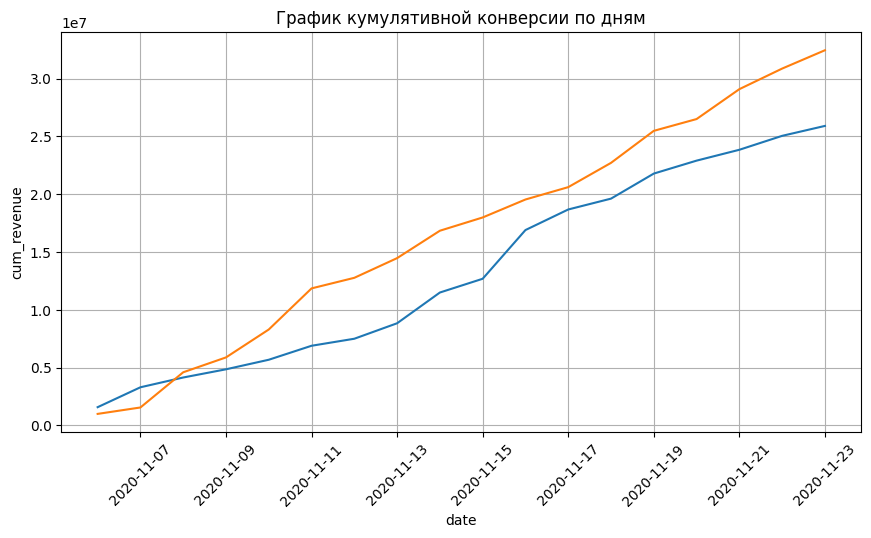

In [15]:
# создаём фигуру размером 8x4
fig = plt.figure(figsize=(8, 4))
# добавляем систему координат
ax = fig.add_axes([1, 1, 1, 1])
# строим lineplot для кумулятивной конверсии во времени в каждой группе
sns.lineplot(x='date', y='cum_revenue', data=daily_data_a, ax=ax)
sns.lineplot(x='date', y='cum_revenue', data=daily_data_b, ax=ax)
# задаём подпись к графику
ax.set_title('График кумулятивной конверсии по дням')
# задаём поворот меток на оси абсцисс
ax.xaxis.set_tick_params(rotation = 45)
# задаём отображение сетки
ax.grid(True);

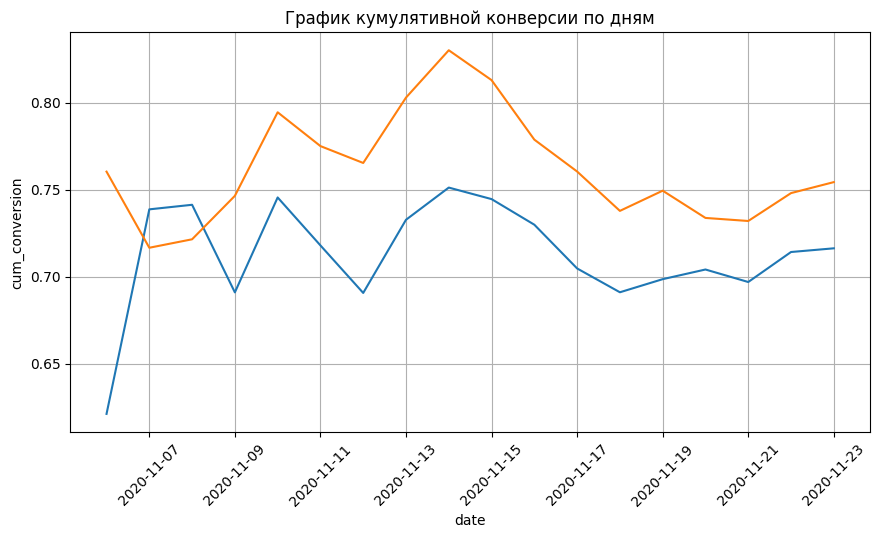

In [16]:
# создаём фигуру размером 8x4
fig = plt.figure(figsize=(8, 4))
# добавляем систему координат
ax = fig.add_axes([1, 1, 1, 1])
# строим lineplot для кумулятивной конверсии во времени в каждой группе
sns.lineplot(x='date', y='cum_conversion', data=daily_data_a, ax=ax)
sns.lineplot(x='date', y='cum_conversion', data=daily_data_b, ax=ax)
# задаём подпись к графику
ax.set_title('График кумулятивной конверсии по дням')
# задаём поворот меток на оси абсцисс
ax.xaxis.set_tick_params(rotation = 45)
# задаём отображение сетки
ax.grid(True);

In [20]:
list_transaction = [sample_a['transactions'].sum(), sample_b['transactions'].sum()]

In [21]:
list_transaction

[np.int64(441), np.int64(463)]

In [22]:
list_cid = [sample_a['cid'].sum(), sample_b['cid'].sum()]

In [17]:
from statsmodels.stats.proportion import proportions_ztest

In [23]:
alpha = 0.05 # уровень значимости
# вычисляем значение p-value для z-теста для пропорций
_, p_value = proportions_ztest(
    count=list_transaction, #число «успехов»
    nobs=list_cid, #общее число наблюдений
    alternative='smaller',
)
# выводим результат на экран
print('p-value: ', round(p_value, 3))
# сравниваем полученное p-value с уровнем значимости
if (p_value <= alpha):
    print("Отвергаем нулевую гипотезу в пользу альтернативной")
else:
    print("У нас нет оснований отвергнуть нулевую гипотезу")

# p-value:  0.19
# У нас нет оснований отвергнуть нулевую гипотезу

p-value:  0.216
У нас нет оснований отвергнуть нулевую гипотезу


In [24]:
daily_sample_a = sample_a.groupby('date')[['transactions', 'revenue']].sum()
daily_sample_a['mean_check'] = daily_sample_a['revenue']/daily_sample_a['transactions']
daily_sample_b = sample_b.groupby('date')[['transactions', 'revenue']].sum()
daily_sample_b['mean_check'] = daily_sample_b['revenue']/daily_sample_b['transactions']

In [25]:
from scipy.stats import shapiro

In [26]:
alpha = 0.05 # уровень значимости
# вычисляем результат теста Шапиро — Уилка для выборок
shapiro_result_a = shapiro(daily_sample_a['mean_check'])
shapiro_result_b = shapiro(daily_sample_b['mean_check'])
print('p-value группы А', round(shapiro_result_a.pvalue, 2))
print('p-value группы B', round(shapiro_result_b.pvalue, 2))

# сравниваем полученное p-value для группы А с уровнем значимости
if shapiro_result_a.pvalue <= alpha:
    print("Отвергаем нулевую гипотезу в пользу альтернативной. Распределение в группе А отлично от нормального")
else:
    print("Принимаем нулевую гипотезу. Распределение в группе А является нормальным")

# сравниваем полученное p-value для группы B с уровнем значимости
if shapiro_result_b.pvalue <= alpha:
    print("Отвергаем нулевую гипотезу в пользу альтернативной. Распределение в группе B отлично от нормального")
else:
    print("Принимаем нулевую гипотезу. Распределение в группе B является нормальным")

# p-value группы А 0.43
# p-value группы B 0.12
# Принимаем нулевую гипотезу. Распределение в группе А является нормальным
# Принимаем нулевую гипотезу. Распределение в группе B является нормальным

p-value группы А 0.01
p-value группы B 0.02
Отвергаем нулевую гипотезу в пользу альтернативной. Распределение в группе А отлично от нормального
Отвергаем нулевую гипотезу в пользу альтернативной. Распределение в группе B отлично от нормального


In [27]:
from scipy.stats import mannwhitneyu

In [29]:
alpha = 0.05 # уровень значимости

# вычисляем результат теста Манна — Уитни для выборок
results = mannwhitneyu(
    x=daily_sample_a['mean_check'],
    y=daily_sample_b['mean_check'],
    alternative='two-sided'
)
print('p-value:', round(results.pvalue, 2))

# сравниваем полученное p-value с уровнем значимости
if results.pvalue <= alpha:
    print("Отвергаем нулевую гипотезу в пользу альтернативной")
else:
    print("У нас нет оснований отвергнуть нулевую гипотезу")

# p-value: 0.06
# У нас нет оснований отвергнуть нулевую гипотезу

p-value: 0.18
У нас нет оснований отвергнуть нулевую гипотезу


In [28]:
alpha = 0.05 # уровень значимости

# вычисляем результат теста Манна — Уитни для выборок
results = mannwhitneyu(
    x=daily_sample_a['mean_check'],
    y=daily_sample_b['mean_check'],
    alternative='less' # изменили альтернативную гипотезу
)
print('p-value:', round(results.pvalue, 2))

# сравниваем полученное p-value с уровнем значимости
if results.pvalue <= alpha:
    print("Отвергаем нулевую гипотезу в пользу альтернативной")
else:
    print("У нас нет оснований отвергнуть нулевую гипотезу")

# p-value: 0.03
# Отвергаем нулевую гипотезу в пользу альтернативной

p-value: 0.09
У нас нет оснований отвергнуть нулевую гипотезу
